In [ ]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

import warnings
warnings.filterwarnings("ignore")

In [ ]:
df = pd.read_csv("Breast_Cancer.csv")
df

,Age,Race,Marital Status,T Stage,N Stage,6th Stage,differentiate,Grade,A Stage,Tumor Size,Estrogen Status,Progesterone Status,Regional Node Examined,Reginol Node Positive,Survival Months,Status
0,68,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,4,Positive,Positive,24,1,60,Alive
1,50,White,Married,T2,N2,IIIA,Moderately differentiated,2,Regional,35,Positive,Positive,14,5,62,Alive
2,58,White,Divorced,T3,N3,IIIC,Moderately differentiated,2,Regional,63,Positive,Positive,14,7,75,Alive
3,58,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,18,Positive,Positive,2,1,84,Alive
4,47,White,Married,T2,N1,IIB,Poorly differentiated,3,Regional,41,Positive,Positive,3,1,50,Alive
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4019,62,Other,Married,T1,N1,IIA,Moderately differentiated,2,Regional,9,Positive,Positive,1,1,49,Alive
4020,56,White,Divorced,T2,N2,IIIA,Moderately differentiated,2,Regional,46,Positive,Positive,14,8,69,Alive
4021,68,White,Married,T2,N1,IIB,Moderately differentiated,2,Regional,22,Positive,Negative,11,3,69,Alive
4022,58,Black,Divorced,T2,N1,IIB,Moderately differentiated,2,Regional,44,Positive,Positive,11,1,72,Alive


In [ ]:
df = pd.read_csv('/content/Breast_Cancer.csv')

In [ ]:

print("Dataset Shape:", df.shape)


Dataset Shape: (4024, 16)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4024 entries, 0 to 4023
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Age                     4024 non-null   int64 
 1   Race                    4024 non-null   object
 2   Marital Status          4024 non-null   object
 3   T Stage                 4024 non-null   object
 4   N Stage                 4024 non-null   object
 5   6th Stage               4024 non-null   object
 6   differentiate           4024 non-null   object
 7   Grade                   4024 non-null   object
 8   A Stage                 4024 non-null   object
 9   Tumor Size              4024 non-null   int64 
 10  Estrogen Status         4024 non-null   object
 11  Progesterone Status     4024 non-null   object
 12  Regional Node Examined  4024 non-null   int64 
 13  Reginol Node Positive   4024 non-null   int64 
 14  Survival Months         4024 non-null   int64 
 15  Stat

In [ ]:

display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Age,4024.0,53.972167,8.963134,30.0,47.0,54.0,61.0,69.0
Tumor Size,4024.0,30.473658,21.119696,1.0,16.0,25.0,38.0,140.0
Regional Node Examined,4024.0,14.357107,8.099675,1.0,9.0,14.0,19.0,61.0
Reginol Node Positive,4024.0,4.158052,5.109331,1.0,1.0,2.0,5.0,46.0
Survival Months,4024.0,71.297962,22.921430,1.0,56.0,73.0,90.0,107.0


In [ ]:

display(df.describe(include="object").T)

,count,unique,top,freq
Race,4024,3,White,3413
Marital Status,4024,5,Married,2643
T Stage,4024,4,T2,1786
N Stage,4024,3,N1,2732
6th Stage,4024,5,IIA,1305
differentiate,4024,4,Moderately differentiated,2351
Grade,4024,4,2,2351
A Stage,4024,2,Regional,3932
Estrogen Status,4024,2,Positive,3755
Progesterone Status,4024,2,Positive,3326


In [ ]:

print("Missing values:")
display(df.isnull().sum())


print("Total duplicate rows:", df.duplicated().sum())

Missing values:


,0
Age,0
Race,0
Marital Status,0
T Stage,0
N Stage,0
6th Stage,0
differentiate,0
Grade,0
A Stage,0
Tumor Size,0


Total duplicate rows: 1


In [ ]:
# Display all copies of duplicated records
duplicates = df[df.duplicated(keep=False)]

print("Duplicated records:")
display(duplicates)

Duplicated records:


,Age,Race,Marital Status,T Stage,N Stage,6th Stage,differentiate,Grade,A Stage,Tumor Size,Estrogen Status,Progesterone Status,Regional Node Examined,Reginol Node Positive,Survival Months,Status
213,63,White,Married,T1,N1,IIA,Moderately differentiated,2,Regional,17,Positive,Positive,9,1,56,Alive
436,63,White,Married,T1,N1,IIA,Moderately differentiated,2,Regional,17,Positive,Positive,9,1,56,Alive


In [ ]:
# Check whether positive nodes exceed examined nodes
invalid_nodes = df[
    df["Reginol Node Positive"] >
    df["Regional Node Examined"]
]

print("Records with positive nodes exceeding examined nodes:")
print("Total:", len(invalid_nodes))

display(invalid_nodes)

Records with positive nodes exceeding examined nodes:
Total: 0


,Age,Race,Marital Status,T Stage,N Stage,6th Stage,differentiate,Grade,A Stage,Tumor Size,Estrogen Status,Progesterone Status,Regional Node Examined,Reginol Node Positive,Survival Months,Status


In [ ]:
# Preserve the original dataset
df_raw = df.copy(deep=True)

# Create the cleaned working dataset
df_clean = df_raw.drop_duplicates().copy()

print("Original dataset:", df_raw.shape)
print("Cleaned dataset:", df_clean.shape)
print("Duplicates remaining:", df_clean.duplicated().sum())

Original dataset: (4024, 16)
Cleaned dataset: (4023, 16)
Duplicates remaining: 0


In [ ]:
# Inspect unique values and their frequencies
categorical_columns = df_clean.select_dtypes(include="object").columns

for column in categorical_columns:
    print(f"\n{column}")
    display(df_clean[column].value_counts(dropna=False))


Race


,count
Race,
White,3412
Other,320
Black,291



Marital Status


,count
Marital Status,
Married,2642
Single,615
Divorced,486
Widowed,235
Separated,45



T Stage 


,count
T Stage,
T2,1786
T1,1602
T3,533
T4,102


... (12 outputs left out)


Progesterone Status


,count
Progesterone Status,
Positive,3325
Negative,698



Status


,count
Status,
Alive,3407
Dead,616


In [ ]:
pd.crosstab(
    df_clean["Grade"],
    df_clean["differentiate"],
    margins=True
)

differentiate,Moderately differentiated,Poorly differentiated,Undifferentiated,Well differentiated,All
Grade,,,,,
anaplastic; Grade IV,0,0,19,0,19
1,0,0,0,543,543
2,2350,0,0,0,2350
3,0,1111,0,0,1111
All,2350,1111,19,543,4023


In [ ]:
# Standardize column names
df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

# Correct the spelling error
df_clean.rename(
    columns={"reginol_node_positive": "regional_node_positive"},
    inplace=True
)

print(df_clean.columns.tolist())

['age', 'race', 'marital_status', 't_stage', 'n_stage', '6th_stage', 'differentiate', 'grade', 'a_stage', 'tumor_size', 'estrogen_status', 'progesterone_status', 'regional_node_examined', 'regional_node_positive', 'survival_months', 'status']


In [ ]:
grade_mapping = {
    "1": "Grade I",
    "2": "Grade II",
    "3": "Grade III",
    "anaplastic; Grade IV": "Grade IV"
}

df_clean["grade_standardized"] = df_clean["grade"].map(grade_mapping)

print("Standardized Grade distribution:")
display(df_clean["grade_standardized"].value_counts(dropna=False))

Standardized Grade distribution:


,count
grade_standardized,
Grade II,2350
Grade III,1111
Grade I,543
NaN,19


In [ ]:
numerical_columns = df_clean.select_dtypes(include="number").columns

display(df_clean[numerical_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
age,4023.0,53.969923,8.963118,30.0,47.0,54.0,61.0,69.0
tumor_size,4023.0,30.477007,21.121253,1.0,16.0,25.0,38.0,140.0
regional_node_examined,4023.0,14.358439,8.100241,1.0,9.0,14.0,19.0,61.0
regional_node_positive,4023.0,4.158837,5.109724,1.0,1.0,2.0,5.0,46.0
survival_months,4023.0,71.301765,22.923009,1.0,56.0,73.0,90.0,107.0


In [ ]:
# Check node values
print("Zero or negative node counts:")

display(
    df_clean[
        (df_clean["regional_node_examined"] <= 0) |
        (df_clean["regional_node_positive"] <= 0)
    ]
)

print(
    "Positive nodes exceeding examined nodes:",
    (df_clean["regional_node_positive"] >
     df_clean["regional_node_examined"]).sum()
)

Zero or negative node counts:


,age,race,marital_status,t_stage,n_stage,6th_stage,differentiate,grade,a_stage,tumor_size,estrogen_status,progesterone_status,regional_node_examined,regional_node_positive,survival_months,status,grade_standardized


Positive nodes exceeding examined nodes: 0


In [ ]:
numerical_columns = df_clean.select_dtypes(include="number").columns

for column in numerical_columns:
    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = (
        (df_clean[column] < lower) |
        (df_clean[column] > upper)
    ).sum()

    print(f"{column}: {count} potential outliers")

age: 0 potential outliers
tumor_size: 222 potential outliers
regional_node_examined: 72 potential outliers
regional_node_positive: 344 potential outliers
survival_months: 18 potential outliers


In [ ]:
Q1 = df_clean["tumor_size"].quantile(0.25)
Q3 = df_clean["tumor_size"].quantile(0.75)
IQR = Q3 - Q1

upper_limit = Q3 + 1.5 * IQR

tumor_outliers = df_clean[
    df_clean["tumor_size"] > upper_limit
]

print("Upper IQR limit:", upper_limit)
print("Potential tumor-size outliers:", len(tumor_outliers))

display(
    tumor_outliers[["age", "tumor_size", "6th_stage", "status"]]
    .sort_values("tumor_size", ascending=False)
    .head(15)
)

Upper IQR limit: 71.0
Potential tumor-size outliers: 222


,age,tumor_size,6th_stage,status
289,41,140,IIIC,Dead
740,49,140,IIIA,Alive
1007,60,140,IIIA,Alive
1512,63,140,IIIB,Alive
3965,47,140,IIIA,Alive
894,47,133,IIIA,Alive
305,57,130,IIIC,Dead
526,45,130,IIIA,Alive
889,46,130,IIIA,Alive
70,49,130,IIIA,Alive


In [ ]:
for column in numerical_columns:
    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    print(f"\n{column}")
    print("Lower boundary:", lower)
    print("Upper boundary:", upper)


age
Lower boundary: 26.0
Upper boundary: 82.0

tumor_size
Lower boundary: -17.0
Upper boundary: 71.0

regional_node_examined
Lower boundary: -6.0
Upper boundary: 34.0

regional_node_positive
Lower boundary: -5.0
Upper boundary: 11.0

survival_months
Lower boundary: 5.0
Upper boundary: 141.0


In [ ]:
Q1 = df_clean["regional_node_positive"].quantile(0.25)
Q3 = df_clean["regional_node_positive"].quantile(0.75)
IQR = Q3 - Q1

upper_limit = Q3 + 1.5 * IQR

node_outliers = df_clean[
    df_clean["regional_node_positive"] > upper_limit
]

print("Upper IQR limit:", upper_limit)
print("Potential outliers:", len(node_outliers))

display(
    node_outliers[
        [
            "regional_node_examined",
            "regional_node_positive",
            "6th_stage",
            "status"
        ]
    ].sort_values(
        "regional_node_positive",
        ascending=False
    ).head(15)
)

Upper IQR limit: 11.0
Potential outliers: 344


,regional_node_examined,regional_node_positive,6th_stage,status
633,54,46,IIIC,Dead
2182,41,41,IIIC,Alive
1128,37,37,IIIC,Alive
989,41,37,IIIC,Alive
1267,36,35,IIIC,Dead
2934,35,34,IIIC,Dead
3017,34,34,IIIC,Alive
838,36,33,IIIC,Dead
3265,33,33,IIIC,Alive
2142,41,32,IIIC,Alive


In [ ]:
df_clean["age_group"] = pd.cut(
    df_clean["age"],
    bins=[29, 39, 49, 59, 69],
    labels=["30-39", "40-49", "50-59", "60-69"]
)

display(df_clean[["age", "age_group"]].head(10))

,age,age_group
0,68,60-69
1,50,50-59
2,58,50-59
3,58,50-59
4,47,40-49
5,51,50-59
6,51,50-59
7,40,40-49
8,40,40-49
9,69,60-69


In [ ]:
df_clean["positive_node_ratio"] = (
    df_clean["regional_node_positive"] /
    df_clean["regional_node_examined"]
)

display(
    df_clean[
        [
            "regional_node_examined",
            "regional_node_positive",
            "positive_node_ratio"
        ]
    ].head(10)
)

,regional_node_examined,regional_node_positive,positive_node_ratio
0,24,1,0.041667
1,14,5,0.357143
2,14,7,0.500000
3,2,1,0.500000
4,3,1,0.333333
5,18,2,0.111111
6,11,1,0.090909
7,9,1,0.111111
8,20,18,0.900000
9,21,12,0.571429


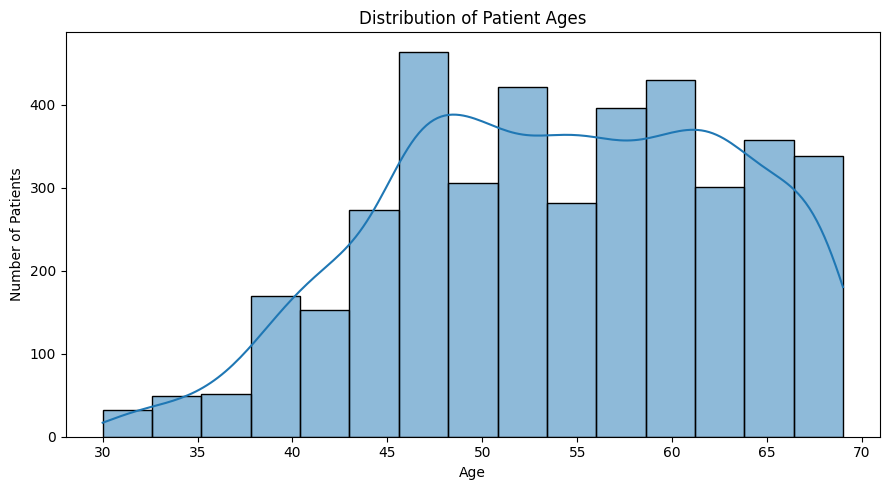

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_clean,
    x="age",
    bins=15,
    kde=True
)

plt.title("Distribution of Patient Ages")
plt.xlabel("Age")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()

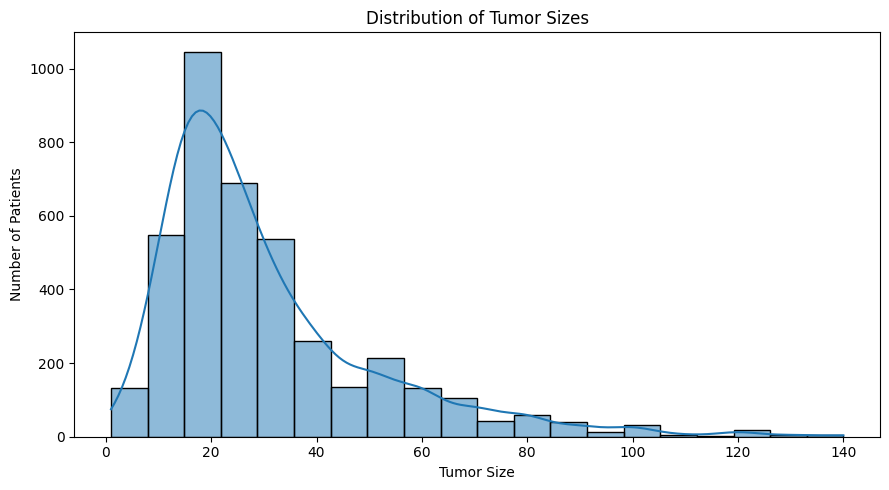

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(data=df_clean, x="tumor_size", bins=20, kde=True)

plt.title("Distribution of Tumor Sizes")
plt.xlabel("Tumor Size")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()

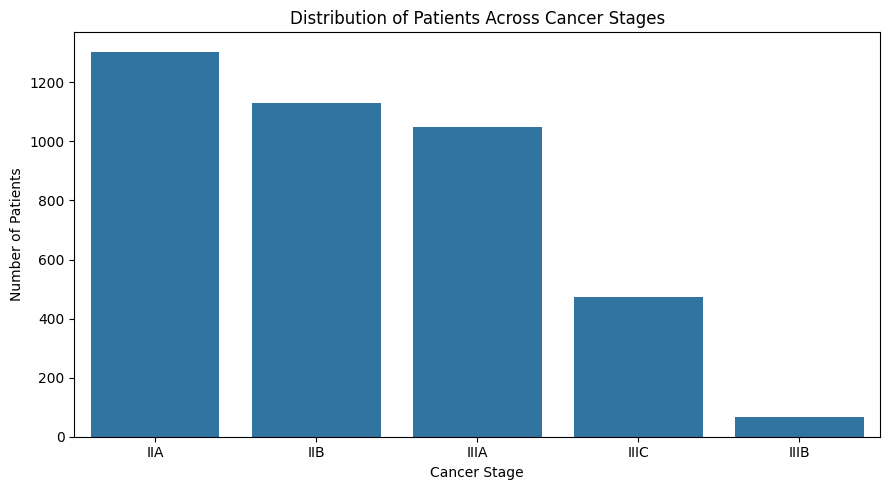

In [ ]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df_clean,
    x="6th_stage",
    order=df_clean["6th_stage"].value_counts().index
)

plt.title("Distribution of Patients Across Cancer Stages")
plt.xlabel("Cancer Stage")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()

In [ ]:
df.to_csv("Breast_Cancer_Cleaned.csv", index=False)

In [ ]:
print(df_clean["grade"].value_counts())

print(df_clean["marital_status"].unique())

grade
2                        2350
3                        1111
1                         543
 anaplastic; Grade IV      19
Name: count, dtype: int64
['Married' 'Divorced' 'Single ' 'Widowed' 'Separated']


In [ ]:
summary = pd.DataFrame({
    "Data Type": df.dtypes,
    "Missing Values": df.isnull().sum(),
    "Missing %": (
        df.isnull().sum() / len(df) * 100
    ).round(2),
    "Unique Values": df.nunique()
})

summary = summary.sort_values(
    "Missing %",
    ascending=False
)

display(summary)


,Data Type,Missing Values,Missing %,Unique Values
Age,int64,0,0.0,40
Race,object,0,0.0,3
Marital Status,object,0,0.0,5
T Stage,object,0,0.0,4
N Stage,object,0,0.0,3
6th Stage,object,0,0.0,5
differentiate,object,0,0.0,4
Grade,object,0,0.0,4
A Stage,object,0,0.0,2
Tumor Size,int64,0,0.0,110


In [ ]:

numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns

# Statistical summary
print(df[numerical_columns].describe())

               Age   Tumor Size  Regional Node Examined  \
count  4024.000000  4024.000000             4024.000000   
mean     53.972167    30.473658               14.357107   
std       8.963134    21.119696                8.099675   
min      30.000000     1.000000                1.000000   
25%      47.000000    16.000000                9.000000   
50%      54.000000    25.000000               14.000000   
75%      61.000000    38.000000               19.000000   
max      69.000000   140.000000               61.000000   

       Reginol Node Positive  Survival Months  
count            4024.000000      4024.000000  
mean                4.158052        71.297962  
std                 5.109331        22.921430  
min                 1.000000         1.000000  
25%                 1.000000        56.000000  
50%                 2.000000        73.000000  
75%                 5.000000        90.000000  
max                46.000000       107.000000  


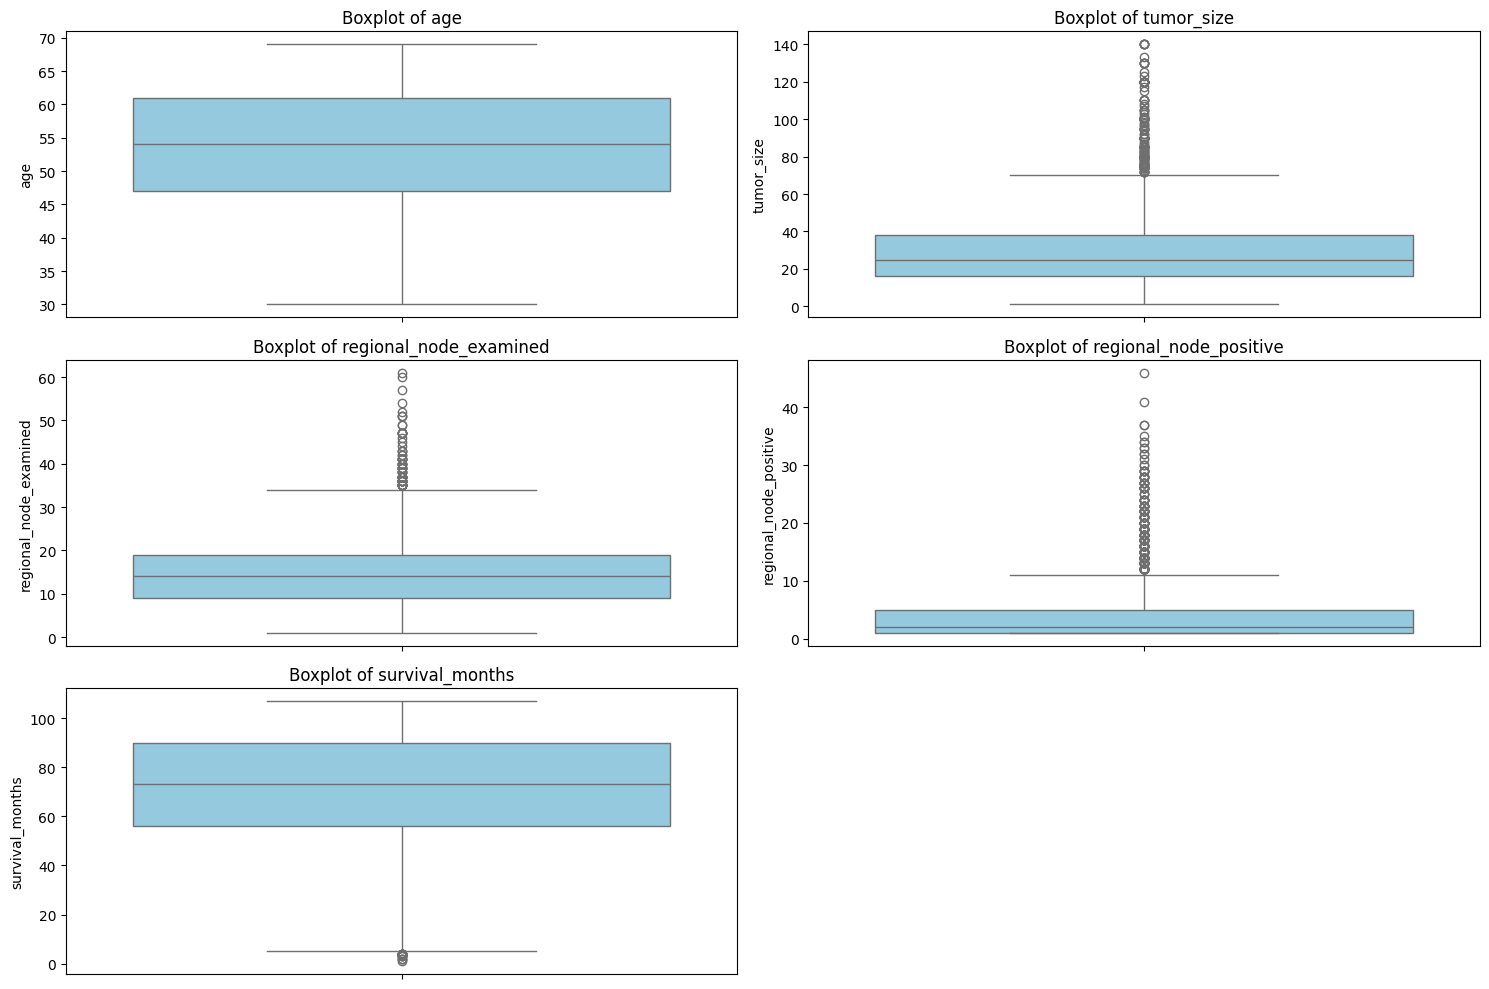

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

numerical_columns = [
    "age",
    "tumor_size",
    "regional_node_examined",
    "regional_node_positive",
    "survival_months"
]

plt.figure(figsize=(15, 10))

for i, column in enumerate(numerical_columns, 1):

    plt.subplot(3, 2, i)

    sns.boxplot(
        y=df_clean[column],
        color="skyblue"
    )

    plt.title(f"Boxplot of {column}")
    plt.ylabel(column)

plt.tight_layout()
plt.show()

In [ ]:

# Select numerical columns
numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns

# Calculate IQR boundaries
for column in numerical_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Keep values within boundaries
    df = df[
        (df[column] >= lower_bound) &
        (df[column] <= upper_bound)
    ]

print("Dataset shape after outlier removal:", df.shape)


Dataset shape after outlier removal: (3267, 16)


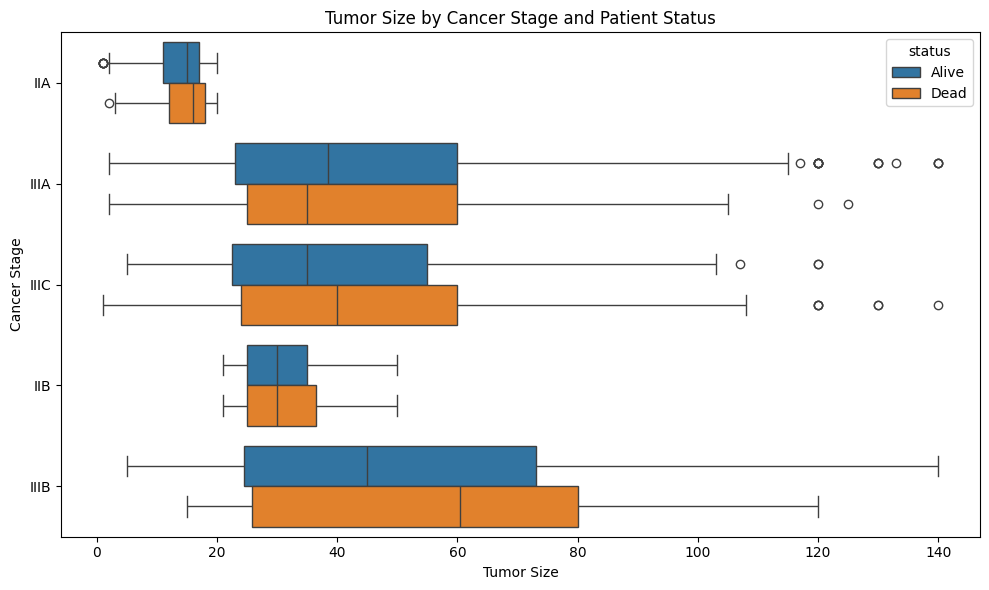

In [ ]:
top_stages = (
    df_clean["6th_stage"]
    .value_counts()
    .head(5)
    .index
)

subset = df_clean[df_clean["6th_stage"].isin(top_stages)]

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=subset,
    x="tumor_size",
    y="6th_stage",
    hue="status"
)

plt.title("Tumor Size by Cancer Stage and Patient Status")
plt.xlabel("Tumor Size")
plt.ylabel("Cancer Stage")

plt.tight_layout()
plt.show()

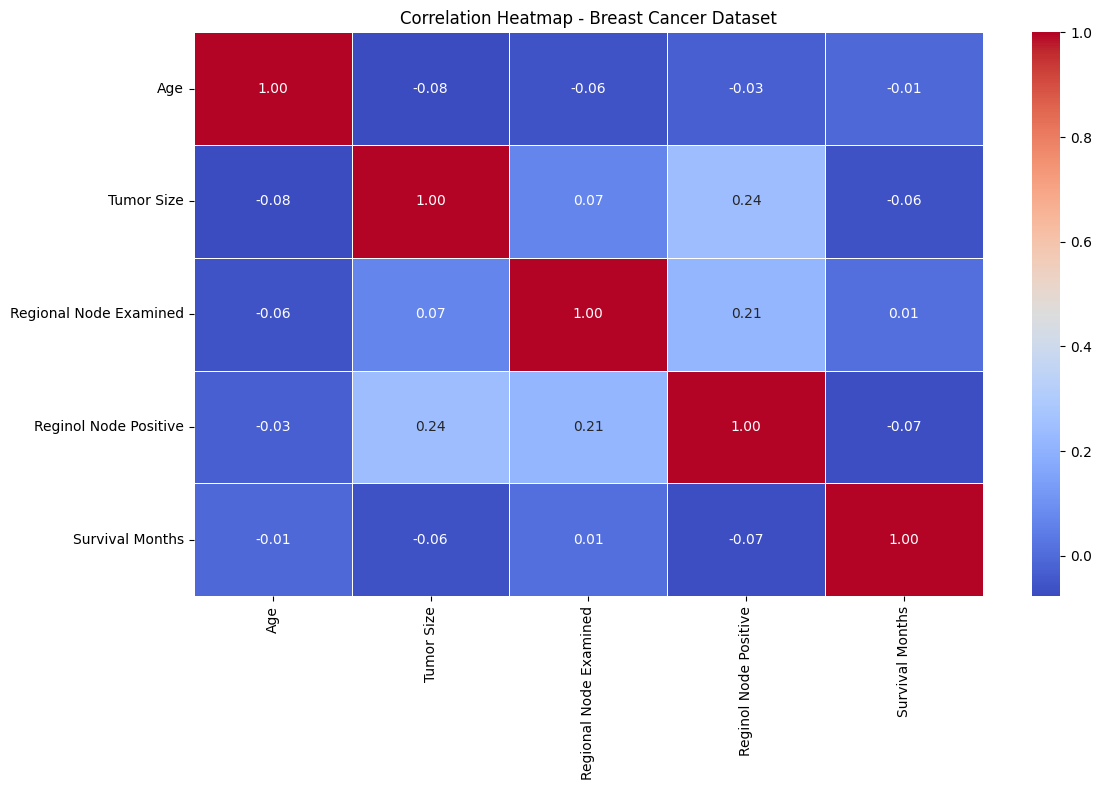

In [ ]:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Select numerical columns
numeric_df = df.select_dtypes(include=["int64", "float64"])

# Create correlation heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Heatmap - Breast Cancer Dataset")
plt.tight_layout()
plt.show()


In [ ]:
monthly_analysis = (
    df_clean.groupby("age")["survival_months"]
    .mean()
    .reset_index()
)

monthly_analysis.head()

,age,survival_months
0,30,67.800000
1,31,55.642857
2,32,66.230769
3,33,70.866667
4,34,67.571429


In [ ]:
stage_analysis = (
    df_clean.groupby("6th_stage")["survival_months"]
    .mean()
    .reset_index()
)

stage_analysis

,6th_stage,survival_months
0,IIA,74.422546
1,IIB,72.223009
2,IIIA,70.188571
3,IIIB,69.417910
4,IIIC,63.218220


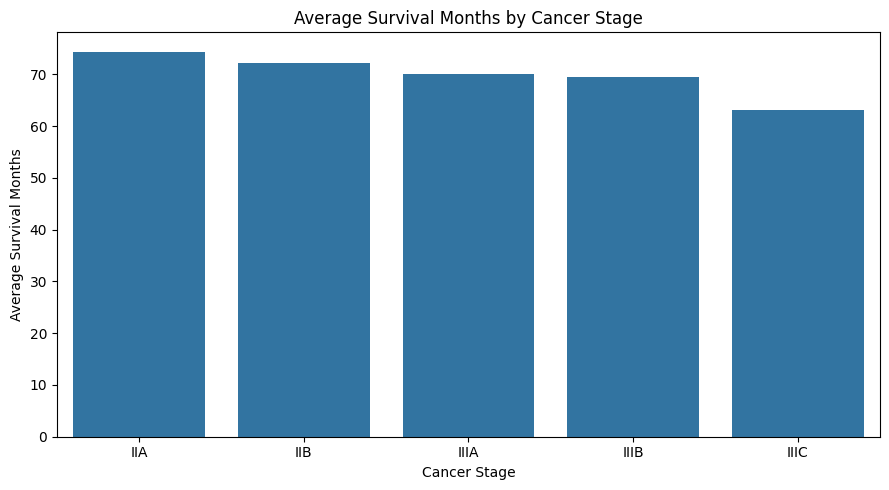

In [ ]:
# Calculate average survival months for each cancer stage
stage_analysis = (
    df_clean.groupby("6th_stage")["survival_months"]
    .mean()
    .reset_index()
)

# Create bar chart
plt.figure(figsize=(9, 5))

sns.barplot(
    data=stage_analysis,
    x="6th_stage",
    y="survival_months"
)

plt.title("Average Survival Months by Cancer Stage")
plt.xlabel("Cancer Stage")
plt.ylabel("Average Survival Months")

plt.tight_layout()
plt.show()

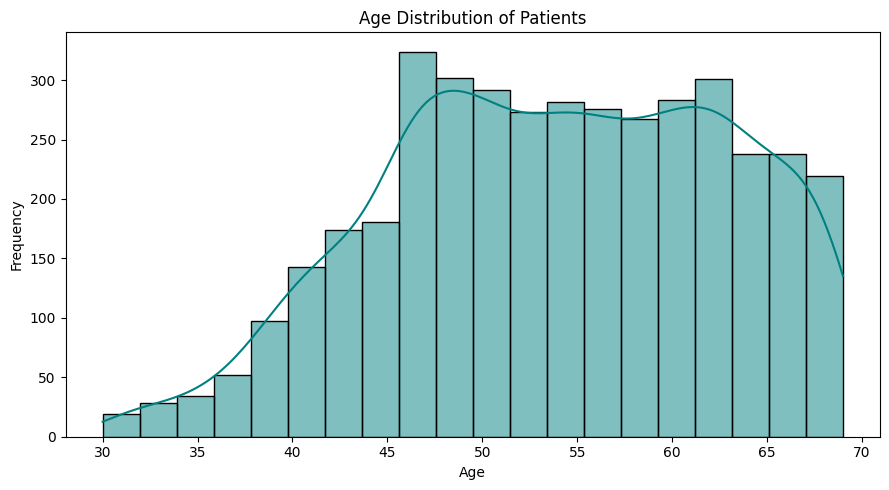

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_clean,
    x="age",
    bins=20,
    kde=True,
    color="teal"
)

plt.title("Age Distribution of Patients")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

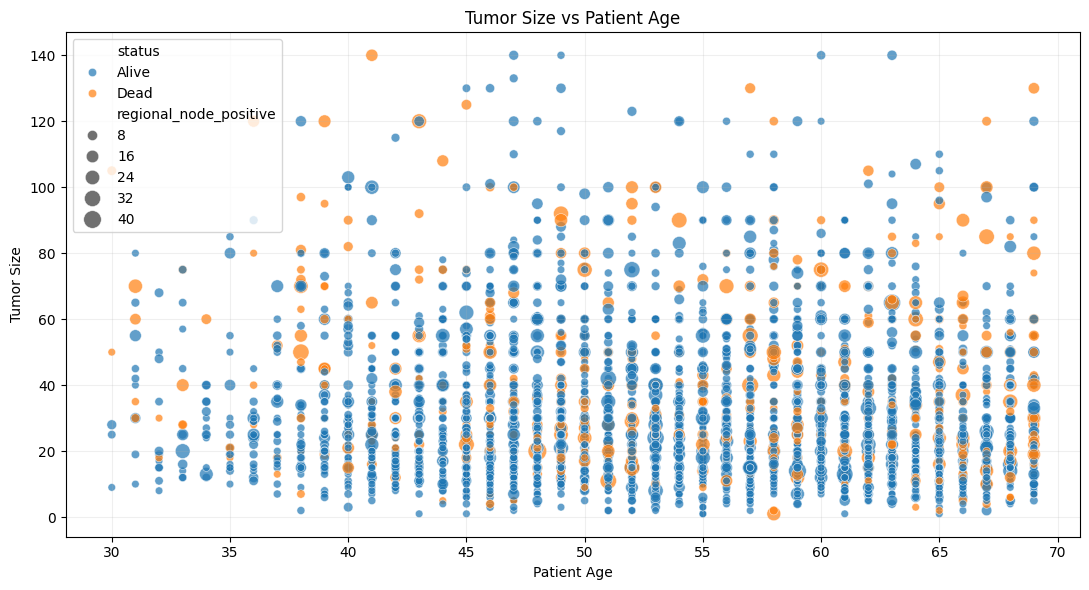

In [ ]:
plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=df_clean,
    x="age",
    y="tumor_size",
    hue="status",
    size="regional_node_positive",
    sizes=(30, 180),
    alpha=0.7
)

plt.title("Tumor Size vs Patient Age")
plt.xlabel("Patient Age")
plt.ylabel("Tumor Size")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [ ]:
!pip install plotly

In [ ]:
fig = px.scatter_3d(
    df_clean,
    x="survival_months",
    y="age",
    z="tumor_size",
    color="status",

    color_discrete_map={
        "Alive": "green",
        "Dead": "red"
    },

    hover_data=[
        "regional_node_positive",
        "6th_stage",
        "grade",
        "race"
    ],

    title="3D Breast Cancer Patient Analysis",

    opacity=0.7
)

fig.update_layout(
    scene=dict(
        xaxis_title="Survival Months",
        yaxis_title="Patient Age",
        zaxis_title="Tumor Size"
    ),
    width=1000,
    height=750,
    template="plotly_dark"
)

fig.show()

In [ ]:
time_columns = [
    column for column in df_clean.columns
    if any(word in column.lower()
           for word in ["date", "year", "month", "time"])
]

print("Time-related columns:", time_columns)

Time-related columns: ['survival_months']


In [ ]:
print("Survival duration summary:")
print(df_clean["survival_months"].describe())

Survival duration summary:
count    4023.000000
mean       71.301765
std        22.923009
min         1.000000
25%        56.000000
50%        73.000000
75%        90.000000
max       107.000000
Name: survival_months, dtype: float64


### ***Time-Series Analysis***

The dataset does not contain calendar-based information such as dates, years, or months. Although it includes a `survival_months` variable, this represents the recorded duration for each patient rather than observations collected at regular time intervals.

Therefore, conventional time-series analysis is not applicable to this dataset. Survival duration has instead been explored through descriptive statistical analysis.

# The Findings and Recommendations

## Key Findings

1. **Patient Age:** The average patient age is approximately 54 years, with a median of 54 years.

2. **Tumour Size:** The average recorded tumour size is approximately 30.48, while the median is 25, indicating that the distribution extends towards larger values.

3. **Patient Status:** The dataset contains 3,407 records classified as Alive and 616 classified as Dead.

4. **Cancer Stage:** Stage IIA is the most frequently recorded stage, with 1,304 records.

5. **Survival Duration:** The average recorded survival duration is approximately 71.3 months, with a median of 73 months.

6. **Data Quality:** One exact duplicate record was removed. No missing values remained, and potential numerical outliers were retained rather than automatically deleted.

## Recommendations

1. Use clear, consistent data standards to maintain the quality of patient records.

2. Explore patient characteristics across age groups and recorded cancer stages through further descriptive analysis.

3. Investigate the differences in tumour-size distributions across recorded patient-status groups without assuming causation.

4. Preserve unusual but valid observations during data cleaning to avoid losing potentially useful information.

5. Use interactive dashboards to make dataset patterns easier to explore and communicate.

## Conclusion

The exploratory data analysis provided an overview of patient characteristics, tumour measurements, cancer stages, and recorded survival information. Data cleaning and feature engineering improved the dataset's consistency and analytical usability.

The findings are descriptive and limited to this dataset. They should not be interpreted as clinical predictions or medical recommendations.